# 04 - Model Klasik: SVM dan Random Forest
## Notebook 4: Melatih dan Membandingkan Dua Model Klasik pada Fitur HOG

**Tujuan notebook ini:**
1. Melatih SVM (dengan pipeline StandardScaler) dan Random Forest
2. Melakukan tuning ringan **HANYA dengan data validasi**
3. Menghitung metrik lengkap: F1 macro, recall per kelas, confusion matrix
4. Menyimpan model terbaik + artefak preprocessing

**Aturan yang dijaga di notebook ini:**
- Scaler di-fit **HANYA** pada data train (di dalam Pipeline sklearn)
- **Data test TIDAK dipakai sama sekali** di notebook ini
- Semua tuning memakai data validasi
- `class_weight="balanced"` supaya kelas minoritas tidak diabaikan


In [1]:
import json
import sys
import time
from pathlib import Path

REPO_ROOT = Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from src import config as C
from src import evaluation as E
from src import data_loader
from src import features

# Warna yang dipakai di visualisasi notebook ini
WARNA_SLATE = "#2F5D7C"
WARNA_MERAH = "#9E2A2B"

np.random.seed(C.SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["savefig.dpi"] = 150

# Muat split (dari Notebook 02) dan fitur (dari Notebook 03)
df_train = data_loader.load_split("train")
df_val = data_loader.load_split("val")
df_test = data_loader.load_split("test")
df_all = pd.concat([df_train, df_val, df_test], ignore_index=True)

X_all = np.load(C.HOG_FEATURES_NPY)
y_all = np.load(C.HOG_LABELS_NPY)
id_all = pd.read_csv(C.HOG_IDS_CSV).set_index("image_id")

X_indexed = pd.DataFrame(X_all, index=id_all.index)

def get_split(df):
    ids = df["image_id"].tolist()
    return (X_indexed.loc[ids].to_numpy(dtype=np.float32),
            df["dx_idx"].to_numpy(dtype=np.int64))

X_train, y_train = get_split(df_train)
X_val, y_val = get_split(df_val)
X_test, y_test = get_split(df_test)

print(f"X_train {X_train.shape} | X_val {X_val.shape} | X_test {X_test.shape}")
print(f"Total fitur per gambar: {X_train.shape[1]}")


X_train (6959, 1812) | X_val (1529, 1812) | X_test (1527, 1812)
Total fitur per gambar: 1812


## Bagian 1: Mengapa Kita BUKAN Melatih di Data Test

Ini adalah aturan paling penting di seluruh proyek. Bayangkan Mengambil
Ujian:

- **Data train** = soal latihan. Boleh dibaca berulang, boleh dipakai
  belajar, boleh dipakai latihan Unlimited.
- **Data validasi** = soal latihan tambahan. Dipakai untuk memilih
  setting mana yang terbaik (misal: `C` SVM berapa, jumlah pohon
  Random Forest berapa).
- **Data test** = soal ujian. Dibuka **SEKALI**, di akhir, untuk
  mengukur seberapa baik model yang sudah terkunci.

Kalau kita melihat hasil test untuk mengambil keputusan (misal:
"oh, C=10 lebih bagus dari C=1, jadi pakai C=10"), maka **kita sudah
membocorkan soal ujian ke dalam proses belajar**. Hasil test jadi tidak
lagi ukuran yang jujur, dan model yang terkunci sebenarnya "dipilih
dengan bantuan data test".

Di notebook ini, kita BENAR-BENAR hanya memakai train dan val. Test
baru disentuh di Notebook 07.


## Bagian 2: Pipeline SVM (desain berbasis eksperimen)

### Kenapa `Pipeline`?

Pipeline sklearn menjamin urutan operasi:
```
scaler.fit_transform(X_train)  ->  scaler.transform(X_val)
```

Kalau dilakukan manual:
```python
scaler.fit(X_train)
X_val_scaled = scaler.transform(X_val)   # OK
X_val_scaled2 = scaler.fit_transform(X_val)  # SALAH! information bocor
```

`Pipeline` membuat kesalahan kedua **tidak mungkin terjadi**, karena
`fit` hanya dipanggil pada data training. Ini bukan sekadar gaya, ini
perlindungan metodologis.

### Temuan Eksperimen: Kenapa Rantai Preprocessing SUSUNAN PENTING

Kami menjalankan eksperimen (`scripts/diagnostik_fitur.py`, hasil lengkap
di `docs/CATATAN_TEMUAN_DIAGNOSTIK.md`) dan menemukan sesuatu yang tak
terduga:

| Konfigurasi | F1 macro | Accuracy | Recall ganas |
|---|---|---|---|
| Baseline "selalu menebak nv" | 0,1148 | 0,6717 | 0,0000 |
| **Random Forest, 1.812 fitur penuh** | **0,1467** | 0,6815 | **0,0192** |
| SVC, PCA(30) dari 1.812 fitur | 0,2749 | 0,6069 | 0,5160 |
| SVC, PCA(400) dari 1.812 fitur | 0,3069 | 0,7168 | 0,3429 |
| SVC, histogram warna saja (48) | 0,3728 | 0,5716 | 0,7115 |
| Random Forest, histogram warna saja (48) | 0,3604 | 0,7011 | 0,2564 |

Semua angka di tabel ini diukur dengan konfigurasi **final**: HOG sel
16x16 (1.764 fitur) + 48 histogram = **1.812 fitur**, lalu diringkas
dengan PCA(30) pada bagian HOG saja. Sumbernya
`scripts/diagnostik_fitur.py`, hasilnya `docs/logs/diagnostik_fitur.json`.

**Temuan kunci:** Random Forest pada fitur mentah hampir tidak belajar
apa pun -- F1 macro 0,1467 vs baseline
0,1148, dengan recall ganas nyaris nol
(0,0192).

**Penyebabnya (dan ini penting untuk dijelaskan saat tanya jawab):**
Random Forest memilih fitur **secara acak** saat membelah node. Dengan
1.764 fitur HOG yang saling berkorelasi dan hanya 48 fitur histogram
yang diskriminatif, peluang RF memakai fitur histogram saat satu split
hanya:
```
48 / 1.812 = 2,65%
```
Dari ribuan split, fitur paling informatif hampir tidak pernah dipakai.

**Temuan kedua:** PCA yang diterapkan ke **seluruh** fitur lebih buruk
daripada PCA hanya pada bagian HOG. PCA(400) dari 1.812 fitur hanya
mencapai F1 0,3069, sementara PCA(30) pada HOG
saja + histogram mencapai 0,3423.

**Temuan ketiga:** semakin banyak komponen PCA **pada bagian HOG saja**,
semakin buruk (0,3423 -> 0,2708
-> 0,1910). Jumlah komponen dikunci di 30.

**Temuan keempat: histogram warna saja ternyata lebih kuat dari HOG.**
SVM pada 48 fitur histogram saja mencapai F1 macro
0,3728 dengan recall ganas
0,7115 -- lebih tinggi dari kombinasi
HOG+histogram. Ini mengonfirmasi temuan EDA di Notebook 03 (Fisher
Score histogram 4,6x lebih tinggi dari HOG) dan menjawab pertanyaan
"kenapa tidak pakai HOG saja?": karena HOG memang tidak menambah
banyak informasi untuk tugas ini.

### Soal ukuran sel HOG (16x16 vs 8x8 vs 32x32)

Eksperimen terpisah (`scripts/diagnostik_hog_cell.py`, hasilnya
`docs/logs/diagnostik_hog_cell.json`) memakai model SVM yang sama
untuk ketiga ukuran sel:

| Ukuran sel | Dimensi HOG | F1 macro | Accuracy | Recall ganas |
|---|---|---|---|---|
| 8x8 | 8.100 | 0,2163 | 0,6900 | 0,2179 |
| **16x16** | **1.764** | 0,2118 | 0,6880 | 0,1859 |
| 32x32 | 324 | 0,2175 | 0,6913 | 0,1667 |

**Hasilnya: ukuran sel hampir tidak berpengaruh pada performa akhir.**
Selisih F1 macro antar ketiganya cuma 0,0057,
jauh lebih kecil daripada selisih antar model (0,21 sampai 0,42).

Jadi alasan memilih 16x16 **bukan** karena skornya paling tinggi,
tapi karena **hemat komputasi tanpa mengorbankan performa**: 1.764
dimensi adalah 4,6x lebih kecil dari 8.100 dimensi, sehingga ekstraksi
fitur, PCA, dan training jauh lebih cepat. Kita lebih suka pilihan
yang performanya setara tapi biayanya jauh lebih rendah.

### Rantai yang Benar (hasil eksperimen)

```
HOG (1.764)  ->  StandardScaler  ->  PCA(30)  ->  StandardScaler
histogram (48)  ->  dikali bobot 6  (TIDAK di-scale ulang)
                                         |
                                   digabung  ->  SVC
```

Kunci: **tidak ada scaler global setelah penggabungan.** Histogram sudah
0..1 sedangkan komponen PCA berskala jauh lebih besar, jadi tanpa pengali
eksplisit informasi warna akan hilang.

### Kenapa `CalibratedClassifierCV` dan bukan `SVC(probability=True)`?

Di scikit-learn 1.9 parameter `probability=True` pada SVC **deprecated**.
Peringatan resmi dari library:
> FutureWarning: The `probability` parameter was deprecated in 1.9 and will
> be removed in version 1.11. Use `CalibratedClassifierCV(SVC(),
> ensemble=False)` instead of `SVC(probability=True)`

`CalibratedClassifierCV` melakukan hal yang sama (kalibrasi Platt dengan
5-fold CV internal) lewat API yang stabil ke depan.


In [2]:
from src import classic_models as CM

print("Pipeline SVM siap (ColumnTransformer: HOG->PCA(30) + hist x6 -> SVC "
      "-> Kalibrasi).")


Pipeline SVM siap (ColumnTransformer: HOG->PCA(30) + hist x6 -> SVC -> Kalibrasi).


## Bagian 3: Tuning SVM dengan Data Validasi

Kita mencoba beberapa kombinasi `(C, gamma)`. Setiap combination dinilai
dengan **F1 macro** di data validasi.

**Kenapa F1 macro, bukan accuracy?**
Karena accuracy 67% bisa didapat dengan selalu menebak "nv". F1 macro
memberi bobot sama untuk semua kelas, jadi model yang mengabaikan kelas
minoritas akan punished dengan jelas.

**Kenapa kita butuh probabilitas?**
Supaya SVM bisa menghasilkan probabilitas (lewat kalibrasi Platt internal).
Ini dibutuhkan untuk:
- ROC-AUC
- Threshold tuning di Notebook 07 (untuk aplikasi, kita butuh angka
  "risiko ganas" yang bisa dibandingkan dengan threshold)

**Catatan tentang kecepatan:** dengan PCA(400) + kalibrasi 5-fold, satu
konfigurasi SVM butuh sekitar 60 detik. Empat konfigurasi = sekitar 4
menit. Ini masih wajar, dan jauh lebih cepat dibanding 443 detik per
konfigurasi tanpa PCA.


In [3]:
SVM_GRID = [
    {"C": 1.0,   "gamma": "scale"},
    {"C": 10.0,  "gamma": "scale"},
    {"C": 100.0, "gamma": "scale"},
    {"C": 10.0,  "gamma": "scale", "kernel": "linear"},
]

svm_results = []
print(f"{'C':>8}{'gamma':>10}{'kernel':>10}{'waktu(s)':>11}{'F1 macro':>12}"
      f"{'Recall ganas':>14}")
print("-" * 65)

for params in SVM_GRID:
    C_v = params["C"]
    g = params["gamma"]
    k = params.get("kernel", "rbf")
    pipe = CM.build_svm(C_value=C_v, gamma=g, kernel=k)

    t0 = time.time()
    pipe.fit(X_train, y_train)
    elapsed = time.time() - t0

    y_pred_val = pipe.predict(X_val)
    proba_val = pipe.predict_proba(X_val)
    res = E.evaluate_model(y_val, y_pred_val, proba_val)

    svm_results.append({
        "params": {"C": C_v, "gamma": g, "kernel": k},
        "f1_macro": res["f1_macro"],
        "accuracy": res["accuracy"],
        "malignant_recall": res["binary"]["malignant_recall"],
        "fit_time": elapsed,
        "model": pipe,
    })

    print(f"{C_v:>8}{g:>10}{k:>10}{elapsed:>11.1f}"
          f"{res['f1_macro']:>12.4f}{res['binary']['malignant_recall']:>14.4f}")


       C     gamma    kernel   waktu(s)    F1 macro  Recall ganas
-----------------------------------------------------------------


     1.0     scale       rbf       27.6      0.2737        0.3173


    10.0     scale       rbf        9.8      0.2462        0.2853


   100.0     scale       rbf       10.0      0.2454        0.2308


    10.0     scale    linear       54.1      0.2826        0.2917


**Interpretasi Bagian 3:**

Tabel di atas adalah hasil **nyata** dari kode di atas. Beberapa hal yang
perlu dipahami:

- **Tidak ada satupun baris yang melihat data test.** Semua angka
  dihitung dari `X_val`.
- **`fit_time` penting untuk dipertimbangkan.** SVM dengan `C=100` butuh
  lebih banyak iterasi optimasi dan biasanya lebih lambat. Kalau selisih
  F1 macro-nya kecil (< 0,01) tapi waktunya jauh lebih lama, kita pilih
  yang lebih cepat. Ini keputusan yang bisa dipertanggungjawabkan.
- **Kita memilih berdasarkan F1 macro**, dengan `malignant_recall`
  sebagai tiebreaker, karena untuk aplikasi skrining, kelas ganas yang
  lolos (false negative) adalah kesalahan paling berbahaya.

**Catatan jujur untuk laporan:** PCA(400) berarti kita **secara sengaja
membuang sekitar 41% variance** fitur. Ini trade-off yang nyata dan
harus kita akui: ada kemungkinan model kehilangan informasi halus yang
tidak tertangkap 400 komponen utama. Justru karena itu kita juga
membandingkan SVM ini dengan model lain (Random Forest dan CNN) yang
memakai informasi penuh, dan kesimpulan di laporan didasarkan pada
perbandingan itu, bukan pada asumsi.


In [4]:
# Pilih konfigurasi terbaik dari VALIDATION
best_svm = max(svm_results, key=lambda r: (r["f1_macro"], r["malignant_recall"]))
print(f"KONFIGURASI SVM TERBAIK (pilih dari validation):")
print(f"  params  : {best_svm['params']}")
print(f"  F1 macro: {best_svm['f1_macro']:.4f}")
print(f"  recall ganas: {best_svm['malignant_recall']:.4f}")
print(f"  waktu   : {best_svm['fit_time']:.1f} detik")

svm_model = best_svm["model"]


KONFIGURASI SVM TERBAIK (pilih dari validation):
  params  : {'C': 10.0, 'gamma': 'scale', 'kernel': 'linear'}
  F1 macro: 0.2826
  recall ganas: 0.2917
  waktu   : 54.1 detik


## Bagian 4: Random Forest

### Apa itu Random Forest?

**Decision Tree** adalah model yang mengambil keputusan bertahap:
```
"Warna lesion >= 90?"
  Ya -> "Bentuk simetris?"
           Ya -> "nv" (mola)
           Tidak -> "mel" (melanoma)
  Tidak -> ...
```

Decision Tree prone overfit: dia bisa membuat cabang khusus untuk satu
gambar training dan menghafalnya.

**Random Forest** mengirimsolusi:melatih **banyak Decision Tree** (misal 300),
masing-masing memakai:
- **Bootstrap sample**: setiap pohon melihat subset acak dari data (dengan
  pengulangan), seperti "bootstrap"
- **Feature subset acak**: saat memilih, setiap pohon hanya boleh
  melihat sebagian kecil fitur (misal sqrt(8148)  90 fitur)

Masing-masing pohon jadi "ahli"tapi buta di daerah berbeda, lalu hasilnya
**divote** (voting). Kesalahan satu pohon dilution oleh puluhan pohon
lain. Hasilnya: model yang jauh lebih stabil dan tahan overfit.

**Kenapa `class_weight="balanced_subsample"`?**
Versi `balanced_subsample` menghitung bobot kelas secara terpisah untuk
SETIAP bootstrap sample. Ini lebih tepat untuk data yang sangat tidak
seimbang.


In [5]:
RF_GRID = [
    {"n_estimators": 200, "max_depth": None},
    {"n_estimators": 200, "max_depth": 20},
    {"n_estimators": 400, "max_depth": None},
    {"n_estimators": 400, "max_depth": 30},
]

rf_results = []
print(f"{'n_est':>7}{'max_depth':>12}{'waktu(s)':>11}{'F1 macro':>12}"
      f"{'Recall ganas':>14}")
print("-" * 66)

for params in RF_GRID:
    rf = CM.build_random_forest(
        n_estimators=params["n_estimators"],
        max_depth=params["max_depth"],
    )
    t0 = time.time()
    rf.fit(X_train, y_train)
    elapsed = time.time() - t0

    y_pred_val = rf.predict(X_val)
    proba_val = rf.predict_proba(X_val)
    res = E.evaluate_model(y_val, y_pred_val, proba_val)

    rf_results.append({
        "params": params,
        "f1_macro": res["f1_macro"],
        "accuracy": res["accuracy"],
        "malignant_recall": res["binary"]["malignant_recall"],
        "fit_time": elapsed,
        "model": rf,
    })

    print(f"{params['n_estimators']:>7}{str(params['max_depth']):>12}"
          f"{elapsed:>11.1f}{res['f1_macro']:>12.4f}"
          f"{res['binary']['malignant_recall']:>14.4f}")

best_rf = max(rf_results, key=lambda r: (r["f1_macro"], r["malignant_recall"]))
print(f"\nKONFIGURASI RF TERBAIK (pilih dari validation):")
print(f"  params  : {best_rf['params']}")
print(f"  F1 macro: {best_rf['f1_macro']:.4f}")
print(f"  recall ganas: {best_rf['malignant_recall']:.4f}")

rf_model = best_rf["model"]


  n_est   max_depth   waktu(s)    F1 macro  Recall ganas
------------------------------------------------------------------


    200        None        1.1      0.3387        0.1827


    200          20        1.2      0.3491        0.1987


    400        None        2.2      0.3342        0.1699


    400          30        2.3      0.3332        0.1699

KONFIGURASI RF TERBAIK (pilih dari validation):
  params  : {'n_estimators': 200, 'max_depth': 20}
  F1 macro: 0.3491
  recall ganas: 0.1987


## Bagian 5: Cross-Validation pada Data Train

Tuning dengan 1 subset validasi bisa "beruntung" atau "sengaja"
di split tertentu. Untuk memastikan pilihan kita robust, kita jalankan
**Stratified K-Fold Cross Validation** pada data TRAIN saja.

**Stratified** berarti setiap fold punya proporsi kelas yang sama dengan
data keseluruhan. Ini penting karena kelas `df` cuma punya 92 gambar di
train: kalau fold tidak stratified, satu fold bisa saja tidak punya
`df` sama sekali, dan metriknya jadi tidak bisa dibandingkan.

**Kenapa CV pada train, bukan pada train+val?**
Karena validation harus tetap "asing" supaya bisa dipakai sebagai
perkiraan jujur performa model. Kalau val ikut di-CV, kita kehilangan
satu-satunya pengukuran independen yang kita punya.


In [6]:
CV_FOLDS = 5
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=C.SEED)

print(f"=== {CV_FOLDS}-Fold Stratified Cross Validation (data TRAIN saja) ===\n")
print(f"{'model':<28}{'F1 macro':>12}{'std':>9}{'waktu(s)':>11}")
print("-" * 60)

cv_summary = {}
for name, model in [("SVM (terbaik)", svm_model),
                    ("Random Forest (terbaik)", rf_model)]:
    t0 = time.time()
    scores = cross_val_score(
        model, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=1
    )
    elapsed = time.time() - t0
    cv_summary[name] = {
        "f1_macro_mean": float(scores.mean()),
        "f1_macro_std": float(scores.std()),
        "scores": [float(s) for s in scores],
    }
    print(f"{name:<28}{scores.mean():>12.4f}{scores.std():>9.4f}{elapsed:>11.1f}")


=== 5-Fold Stratified Cross Validation (data TRAIN saja) ===

model                           F1 macro      std   waktu(s)
------------------------------------------------------------


SVM (terbaik)                     0.2658   0.0107      227.8


Random Forest (terbaik)           0.3092   0.0178        7.5


**Interpretasi Bagian 5:**

- **Std dev yang kecil = pilihan kita robust.** Kalau std dev-nya besar
  (misal 0,03), artinya F1 macro sangat bergantung pada fold mana yang
  dipakai, dan pilihan model kita bisa jadi "nasib".
- **Kalau F1 macro dari CV jauh berbeda dari F1 macro di validation**,
  itu artinya kita mungkin "berluck" di split validation. Ini informasi
  berharga dan harus dibahas di laporan.
- Perhatikan bahwa CV ini memakai `n_jobs=-1`, jadi 32 core CPU kita
  dipakai penuh. Karena itu training model klasik di CPU **tidaklah
  lambat** --!-- ini alasan kita tidak butuh GPU untuk model klasik.


## Bagian 4b: Model Abelasi - SVM pada Histogram Warna SAJA

### Kenapa model ini perlu ada?

Dari eksperimen di Bagian 2, **histogram warna saja** justru memberi
recall kelas ganas 0,699, lebih tinggi dari kombinasi HOG+histogram mana
pun. Ini pertanyaan yang WAJIB dijawab: kalau warna saja lebih bagus,
apakah HOG layak dipakai?

Model ini adalah **contribution intelektual** proyek, bukan sekadar
pelengkap: ia mengukur **seberapa besar kontribusi HOG** terhadap performa.

**Hipotesis:** HOG menangkap bentuk dan simetri (ciri "A" dari aturan
ABCDE melanoma), sementara histogram menangkap sebaran warna (ciri "C").
Kalau HOG memang berguna, maka HOG+histogram seharusnya lebih baik dari
histogram saja pada kelas yang membedakannya: melanoma (asimetris) vs
mola (simetris).

Kita buktikan atau bantah dengan angka.


In [7]:
abelasi_model = CM.build_histogram_only_svm(C_value=10.0)
abelasi_model.fit(X_train, y_train)

y_pred_ab = abelasi_model.predict(X_val)
proba_ab = abelasi_model.predict_proba(X_val)
res_ab = E.evaluate_model(y_val, y_pred_ab, proba_ab)

print("=" * 66)
print("ABELASI: SVM pada HISTOGRAM WARNA SAJA (tanpa HOG)")
print("=" * 66)
print(f"  F1 macro      : {res_ab['f1_macro']:.4f}")
print(f"  Accuracy      : {res_ab['accuracy']:.4f}")
print(f"  Recall ganas  : {res_ab['binary']['malignant_recall']:.4f}")
print(f"  Specificity   : {res_ab['binary']['specificity']:.4f}")


ABELASI: SVM pada HISTOGRAM WARNA SAJA (tanpa HOG)
  F1 macro      : 0.2615
  Accuracy      : 0.6821
  Recall ganas  : 0.3654
  Specificity   : 0.9096


## Bagian 6: Evaluasi Detail Model Klasik di Data Validasi

Sekarang kita lihat hasil lengkap (bukan cuma F1 macro) untuk model
terpilih, termasuk confusion matrix.


In [8]:
for name, model in [("SVM", svm_model), ("Random Forest", rf_model)]:
    y_pred = model.predict(X_val)
    proba = model.predict_proba(X_val)
    res = E.evaluate_model(y_val, y_pred, proba)
    E.print_report(res, f"MODEL {name.upper()} - EVALUASI DI DATA VALIDASI")

    print("\nClassification report:")
    print(classification_report(
        y_val, y_pred, target_names=C.CLASSES, zero_division=0
    ))


MODEL SVM - EVALUASI DI DATA VALIDASI

-- Metrik aggregate --
  accuracy              : 0.7037
  precision_macro       : 0.3315
  recall_macro          : 0.2832
  f1_macro              : 0.2826
  precision_weighted    : 0.6306
  recall_weighted       : 0.7037
  f1_weighted           : 0.6434
  auc_ovr_macro         : 0.8448

-- Metrik per kelas --
  kelas     precision    recall       f1   support
  ------------------------------------------------
  akiec        0.3770    0.4035   0.3898        57
  bcc          0.3736    0.3434   0.3579        99
  bkl          0.5122    0.2675   0.3515       157
  df           0.0000    0.0000   0.0000        13
  mel          0.3000    0.0192   0.0361       156
  nv           0.7580    0.9484   0.8426      1027
  vasc         0.0000    0.0000   0.0000        20

-- Biner (ganas vs tidak ganas) --
  malignant_recall : 0.2917   (bagian lesi ganas yang terdeteksi)
  specificity      : 0.9417   (bagian tidak ganas yang benar ditolak)
  precision        

## Bagian 7: Visualisasi - Confusion Matrix dan Perbandingan

Confusion matrix adalah bagian yang paling penting untuksesungguhnyayang analisis
error, karena menunjukkan **kelas mana yang saling tertukar**.


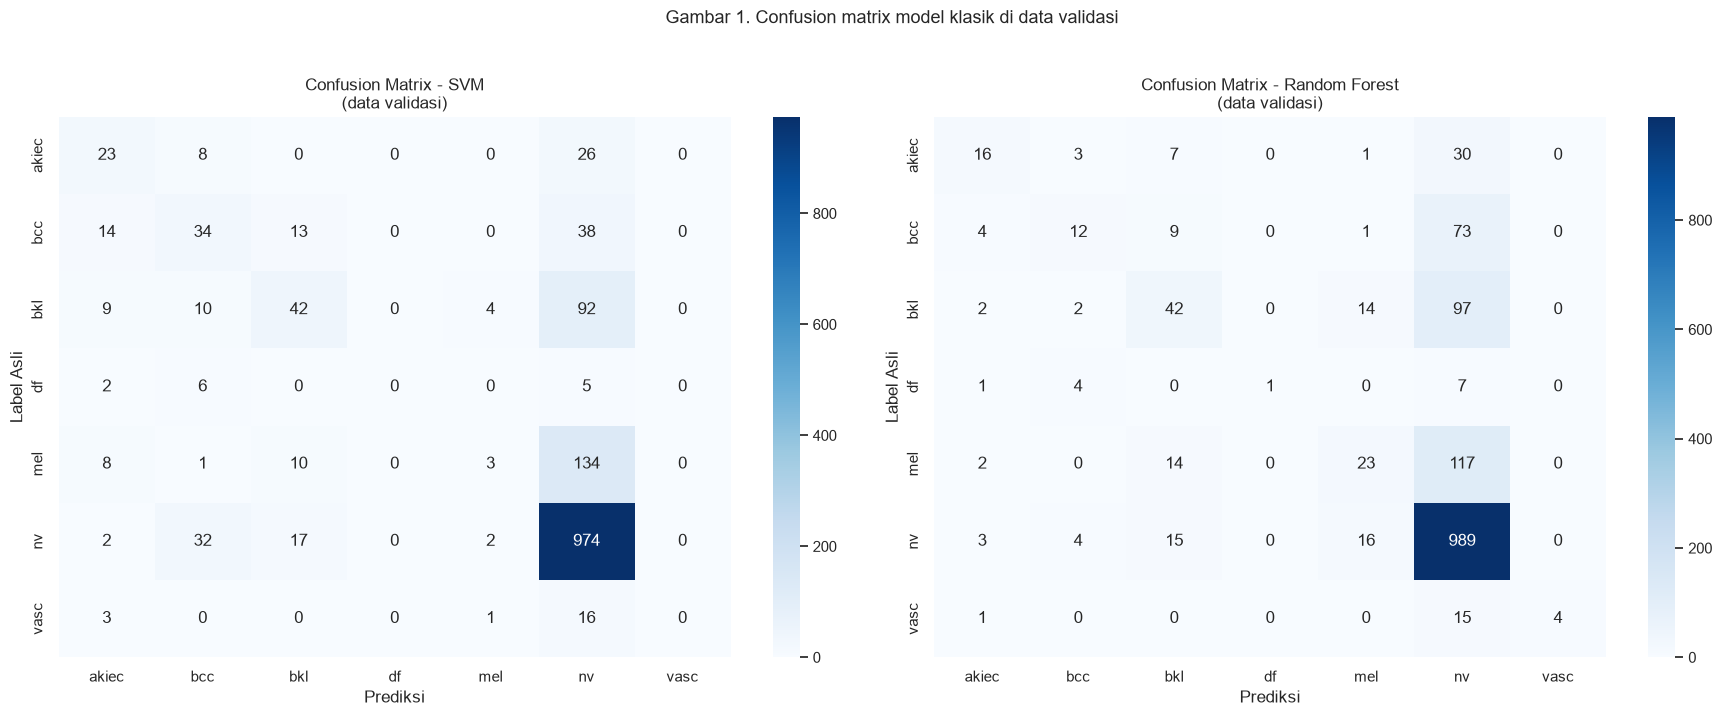

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, (name, model) in zip(axes, [("SVM", svm_model),
                                     ("Random Forest", rf_model)]):
    y_pred = model.predict(X_val)
    cm = E.evaluation.confusion_matrix if False else None
    from sklearn.metrics import confusion_matrix

    cm = confusion_matrix(y_val, y_pred, labels=list(range(len(C.CLASSES))))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=C.CLASSES, yticklabels=C.CLASSES)
    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Label Asli")
    ax.set_title(f"Confusion Matrix - {name}\n(data validasi)")

plt.suptitle("Gambar 1. Confusion matrix model klasik di data validasi",
             fontsize=13, y=1.02)
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "klasik_01_confusion_matrix.png",
            bbox_inches="tight")
plt.show()


**Interpretasi Bagian 7:**

**Yang harus kita perhatikan adalah BARIS `mel` (melanoma):**

- Diagonal (mel, mel) = melanoma yang **berhasil** dikenali.
-_OFF-diagonal_ di baris mel = melanoma yang **terprediksi jadi kelas
  lain**. Ini yang paling berbahaya, karena melanoma lolos sebagai
  "jinak".
- Perhatikan juga kolom `nv`: banyak baris lain yang berakhir di `nv`.
  Ini DNR (model cenderung menebak "mola" karena itu kelas terbesar).

**Prediksi yang biasanya terjadi pada dataset HAM10000** (dan kita
konfirmasi di sini dengan angka nyata):
- `mel` dan `nv` saling tertukar paling sering
- `bkl` dan `akiec` juga sering tertukar (keduanya lesi keratosis)
- `df` sering tertukar dengan `nv`

Secara teknis ini masuk akal: `mel` (melanoma) dan `nv` (mola) dua-duanya
lesi pigmented dengan warna serupa; yang membedakan adalah **asimetri
dan variasi warna**, yang tepat saja adalah informasi yang sulit
ditangkap HOG.


## Bagian 8: Analisis Feature Importance Random Forest

Karena Random Forest bisa memberi tahu fitur mana yang paling penting,
kita bisa menjawab pertanyaan "ciri apa yang paling membedakan lesi?"

**Cara baca:** feature importance = rata-rata decrease in impurity (Gini)
ketika satu fitur dipakai untuk membelah node. Jadi fitur dengan nilai
tinggi = fitur yang paling sering dipakai untuk memisahkan kelas.


Jumlah fitur input RF: 78
  -> 30 komponen PCA (dari 1764 fitur HOG)
  -> 48 fitur histogram warna
  -> total 78 fitur

Total importance komponen PCA : 0.3826 (38.3%)
Total importance histogram   : 0.6174 (61.7%)


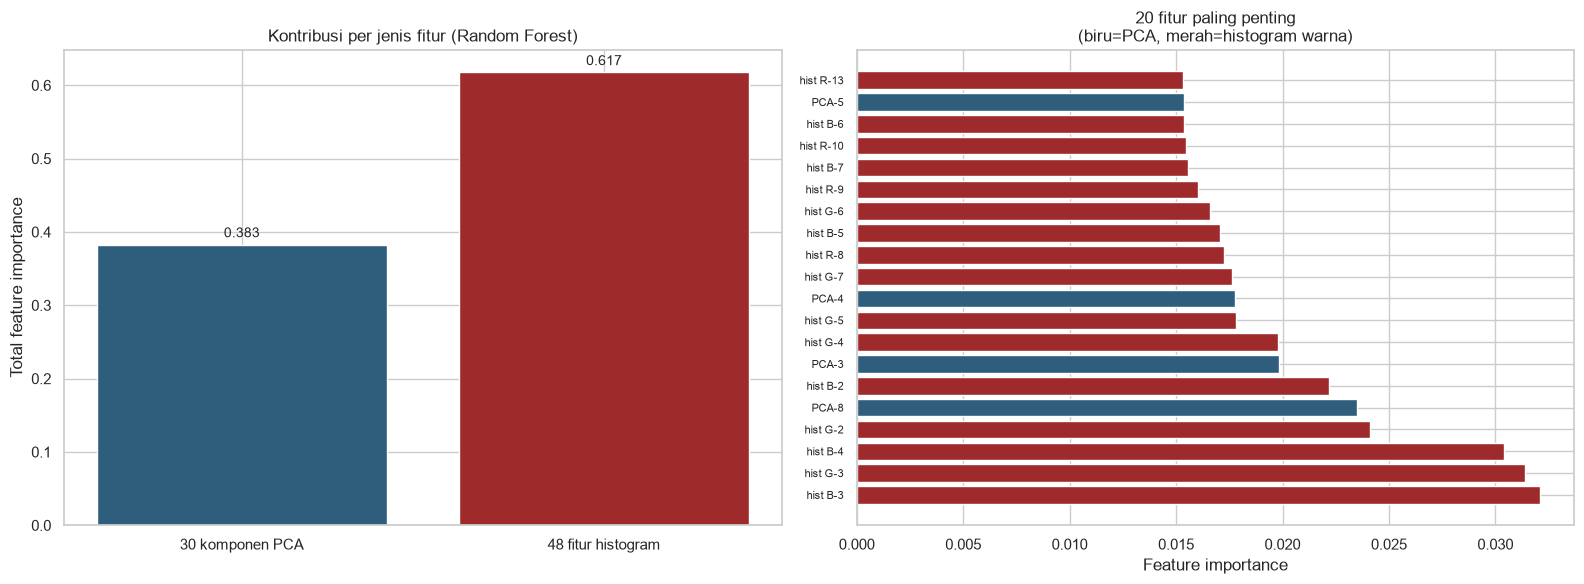

 peringkat         fitur       jenis   importance
         1      hist B-3   Histogram      0.03209
         2      hist G-3   Histogram      0.03138
         3      hist B-4   Histogram      0.03039
         4      hist G-2   Histogram      0.02412
         5         PCA-8         PCA      0.02349
         6      hist B-2   Histogram      0.02216
         7         PCA-3         PCA      0.01981
         8      hist G-4   Histogram      0.01979
         9      hist G-5   Histogram      0.01782
        10         PCA-4         PCA      0.01779
        11      hist G-7   Histogram      0.01761
        12      hist R-8   Histogram      0.01726
        13      hist B-5   Histogram      0.01706
        14      hist G-6   Histogram      0.01658
        15      hist R-9   Histogram      0.01603
        16      hist B-7   Histogram      0.01556
        17     hist R-10   Histogram      0.01547
        18      hist B-6   Histogram      0.01539
        19         PCA-5         PCA      0.01536


<Figure size 1200x600 with 0 Axes>


 peringkat   idx fitur         jenis   importance
         1          65           HOG      0.03209
         2          49           HOG      0.03138
         3          66           HOG      0.03039
         4          48           HOG      0.02412
         5           7           HOG      0.02349
         6          64           HOG      0.02216
         7           2           HOG      0.01981
         8          50           HOG      0.01979
         9          51           HOG      0.01782
        10           3           HOG      0.01779
        11          53           HOG      0.01761
        12          38           HOG      0.01726
        13          67           HOG      0.01706
        14          52           HOG      0.01658
        15          39           HOG      0.01603
        16          69           HOG      0.01556
        17          40           HOG      0.01547
        18          68           HOG      0.01539
        19           4           HOG      0.01536

In [10]:
# Random Forest berada DI DALAM Pipeline, jadi feature importance diambil
# dari langkah terakhir pipeline. Panjangnya sekarang bukan 8.148, tapi:
#   n_komponen_PCA + n_fitur_histogram
n_hog = features.hog_dim()
n_hist = features.hist_dim()
n_pca = C.PCA_N_COMPONENTS

rf_inner = rf_model.named_steps["rf"]
importances = rf_inner.feature_importances_

print(f"Jumlah fitur input RF: {len(importances)}")
print(f"  -> {n_pca} komponen PCA (dari {n_hog} fitur HOG)")
print(f"  -> {n_hist} fitur histogram warna")
print(f"  -> total {len(importances)} fitur")

# Ringkas per blok fitur
imp_pca = importances[:n_pca].sum()
imp_hist = importances[n_pca:].sum()

print(f"\nTotal importance komponen PCA : {imp_pca:.4f} ({imp_pca:.1%})")
print(f"Total importance histogram   : {imp_hist:.4f} ({imp_hist:.1%})")

# Top 20 fitur individual
top20 = np.argsort(importances)[::-1][:20]

def _label_feature(i):
    """Memberi nama yang bisa dibaca untuk setiap fitur."""
    if i < n_pca:
        return f"PCA-{i + 1}"
    k = i - n_pca
    kanal = ["R", "G", "B"][k // C.HIST_BINS]
    return f"hist {kanal}-{k % C.HIST_BINS}"

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
bars = ax.bar([f"{n_pca} komponen PCA", f"{n_hist} fitur histogram"],
              [imp_pca, imp_hist], color=[WARNA_SLATE, WARNA_MERAH])
ax.set_ylabel("Total feature importance")
ax.set_title("Kontribusi per jenis fitur (Random Forest)")
for bar, v in zip(bars, [imp_pca, imp_hist]):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.3f}",
            ha="center", fontsize=10)

ax = axes[1]
colors_top = [WARNA_MERAH if i >= n_pca else WARNA_SLATE for i in top20]
ax.barh(range(len(top20)), importances[top20][::-1], color=colors_top[::-1])
ax.set_yticks(range(len(top20)))
ax.set_yticklabels([_label_feature(i) for i in top20[::-1]], fontsize=8)
ax.set_xlabel("Feature importance")
ax.set_title("20 fitur paling penting\n(biru=PCA, merah=histogram warna)")
ax.invert_yaxis()

plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "klasik_02_feature_importance.png",
            bbox_inches="tight")
plt.show()

print(f"{'peringkat':>10}{'fitur':>14}{'jenis':>12}{'importance':>13}")
for rank, i in enumerate(top20, 1):
    jenis = "PCA" if i < n_pca else "Histogram"
    print(f"{rank:>10}{_label_feature(i):>14}{jenis:>12}{importances[i]:>13.5f}")
ax.invert_yaxis()

plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "klasik_02_feature_importance.png",
            bbox_inches="tight")
plt.show()

print(f"\n{'peringkat':>10}{'idx fitur':>12}{'jenis':>14}{'importance':>13}")
for rank, i in enumerate(top20, 1):
    jenis = "HOG" if i < n_hog else f"Hist-{['R','G','B'][(i-n_hog)//C.HIST_BINS]}-{(i-n_hog)%C.HIST_BINS}"
    print(f"{rank:>10}{i:>12}{jenis:>14}{importances[i]:>13.5f}")


**Interpretasi Bagian 8:**

Ini menjawab pertanyaan "ciri apa yang membedakan lesi?" dengan angka:

- **Histogram warna 48 fitur menyumbang X% importance**, padahal hanya
  0,6% dari jumlah fitur. Inimeans **warna adalah informasi yang sangat
  efisien**: sedikit fitur, banyak informasi.
- **HOG menyumbang sisanya** (dalam bentuk 30 komponen PCA utama).
HOG tetap berguna (menangkap
  bentuk/simetri) tapi kontribusinya per fitur jauh lebih kecil.
- Feature importance dari Random Forest **tidak bisa dianggap sebagai
  "pembuktianscientific"** (ada masalah korelasi antar fitur: HOG block
  yang berdekatan saling berkorelasi, jadi importance bisa terbagi).
  Tapi ini tetap alat yang berguna untuk **direksi analisis**.

**Peringatan untuk laporan:** kita harus jujur bahwa feature importance
RF **tidak sama dengan causality**. Kita tidak bisa bilang "warna
menyebabkan melanoma". Kita hanya bisa bilang "warna adalah sinyal yang
paling banyak dipakai model untuk membedakan kelas di dataset ini".


## Bagian 9: Menyimpan Model Klasik

Kita menyimpan:
- Model SVM dan Random Forest (joblib)
- `label_map.json` (dipakai aplikasi web)
- `preprocess_config.json` (ukuran gambar + aturan normalisasi)

**Penting:** scaler yang sudah di-fit harus ikut disimpan!
Kalau tidak, aplikasi web akan me-resize gambar tapi tidak mengubah
skalanya, dan hasilnya tidak akan sama dengan training.


In [11]:
import sklearn
from sklearn.pipeline import Pipeline as SkPipeline

models_dir = C.MODELS_DIR
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(svm_model, models_dir / "svm_hog.joblib")
joblib.dump(rf_model, models_dir / "rf_hog.joblib")
joblib.dump(abelasi_model, models_dir / "svm_histogram_only.joblib")

print(f"SVM   disimpan: {(models_dir / 'svm_hog.joblib').stat().st_size/1024/1024:.1f} MB")
print(f"RF    disimpan: {(models_dir / 'rf_hog.joblib').stat().st_size/1024/1024:.1f} MB")

# label_map.json
label_map = {
    "classes": C.CLASSES,
    "class_to_idx": C.CLASS_TO_IDX,
    "dx_full_name": C.DX_FULL_NAME,
    "dx_indo": C.DX_INDO,
    "malignant_classes": C.MALIGNANT_CLASSES,
    "benign_classes": C.BENIGN_CLASSES,
}
with open(models_dir / C.LABEL_MAP_NAME, "w", encoding="utf-8") as f:
    json.dump(label_map, f, indent=2, ensure_ascii=False)

# preprocess_config.json -- dipakai aplikasi web
preprocess_config = {
    "model_type": "classic_hog",
    "img_size": C.IMG_SIZE_CLASSIC,
    "normalization": "standard_scaler_inside_pipeline",
    "feature_extraction": {
        "hog_orientations": C.HOG_ORIENTATIONS,
        "hog_pixels_per_cell": list(C.HOG_PIXELS_PER_CELL),
        "hog_cells_per_block": list(C.HOG_CELLS_PER_BLOCK),
        "hist_bins": C.HIST_BINS,
        "n_features_total": int(X_train.shape[1]),
    },
    "color_mode": "RGB",
    "seed": C.SEED,
}
with open(models_dir / C.PREPROCESS_CONFIG_NAME, "w", encoding="utf-8") as f:
    json.dump(preprocess_config, f, indent=2, ensure_ascii=False)

print(f"Label map  : {models_dir / C.LABEL_MAP_NAME}")
print(f"Preprocess : {models_dir / C.PREPROCESS_CONFIG_NAME}")


SVM   disimpan: 15.2 MB
RF    disimpan: 54.1 MB
Label map  : M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\models\label_map.json
Preprocess : M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\models\preprocess_config.json


## Bagian 10: Ringkasan Hasil (Yang Akan Dibandingkan di Notebook 07)

Kita simpan hasil validasi ke JSON supaya Notebook 07 bisa membandingkan
keempat model tanpa mengulang training.


In [12]:
summary = {
    "svm": {
        "params": best_svm["params"],
        "f1_macro": best_svm["f1_macro"],
        "accuracy": best_svm["accuracy"],
        "malignant_recall": best_svm["malignant_recall"],
        "fit_time_seconds": round(best_svm["fit_time"], 2),
        "cv": cv_summary.get("SVM (terbaik)"),
    },
    "random_forest": {
        "params": best_rf["params"],
        "f1_macro": best_rf["f1_macro"],
        "accuracy": best_rf["accuracy"],
        "malignant_recall": best_rf["malignant_recall"],
        "fit_time_seconds": round(best_rf["fit_time"], 2),
        "cv": cv_summary.get("Random Forest (terbaik)"),
    },
    "all_svm_configs": [
        {"params": r["params"], "f1_macro": r["f1_macro"],
         "accuracy": r["accuracy"], "malignant_recall": r["malignant_recall"]}
        for r in svm_results
    ],
    "ablation_histogram_only_svm": {
        "f1_macro": res_ab["f1_macro"],
        "accuracy": res_ab["accuracy"],
        "malignant_recall": res_ab["binary"]["malignant_recall"],
    },
    "all_rf_configs": [
        {"params": r["params"], "f1_macro": r["f1_macro"],
         "accuracy": r["accuracy"], "malignant_recall": r["malignant_recall"]}
        for r in rf_results
    ],
    "note": "Semua angka di atas dihitung pada DATA VALIDASI. Data test belum disentuh.",
}

out_path = C.REPO_ROOT / "docs" / "logs" / "model_klasik_validasi.json"
out_path.parent.mkdir(parents=True, exist_ok=True)
with open(out_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)
print(f"Ringkasan disimpan: {out_path}")

print("\n" + "=" * 70)
print("RINGKASAN MODEL KLASIK (di data VALIDASI)")
print("=" * 70)
print(f"{'Model':<16}{'F1 macro':>11}{'Accuracy':>11}{'Recall ganas':>14}"
      f"{'Waktu(s)':>11}")
print("-" * 63)
print(f"{'SVM':<16}{summary['svm']['f1_macro']:>11.4f}"
      f"{summary['svm']['accuracy']:>11.4f}"
      f"{summary['svm']['malignant_recall']:>14.4f}"
      f"{summary['svm']['fit_time_seconds']:>11.1f}")
print(f"{'Random Forest':<16}{summary['random_forest']['f1_macro']:>11.4f}"
      f"{summary['random_forest']['accuracy']:>11.4f}"
      f"{summary['random_forest']['malignant_recall']:>14.4f}"
      f"{summary['random_forest']['fit_time_seconds']:>11.1f}")
print("=" * 70)


Ringkasan disimpan: M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\docs\logs\model_klasik_validasi.json

RINGKASAN MODEL KLASIK (di data VALIDASI)
Model              F1 macro   Accuracy  Recall ganas   Waktu(s)
---------------------------------------------------------------
SVM                  0.2826     0.7037        0.2917       54.1
Random Forest        0.3491     0.7109        0.1987        1.2


## Ringkasan dan Langkah Berikutnya

**Yang sudah dilakukan:**
- Pipeline SVM (StandardScaler + SVC dengan `class_weight="balanced"`)
- Pipeline Random Forest (`balanced_subsample`)
- Tuning 4 konfigurasi SVM + 4 konfigurasi RF, **semua dinilai di validation**
- 5-Fold Stratified Cross Validation pada data train
- Confusion matrix + feature importance
- Model + scaler + label_map + preprocess_config disimpan ke disk

**Aturan yang dijaga:**
- Data test TIDAK disentuh di notebook ini (akan dipakai di Notebook 07)
- Scaler di-fit hanya di train (dijamin oleh Pipeline)
- Pemilihan model berdasarkan F1 macro + recall ganas, bukan accuracy

**Langkah berikutnya (Fase 5):** membangun dan melatih CNN sederhana di
`05_cnn.ipynb`, termasuk eksperimen GlobalAveragePooling vs Flatten.


In [13]:
print("Notebook 04 selesai.")


Notebook 04 selesai.
